<a href="https://colab.research.google.com/github/ralucapestritu/ML_Seminar_Pestritu-BoborocRaluca/blob/main/lp4_modele_de_regresie.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LP5 – Modele de regresie

**Obiective.** După acest laborator veți putea:
- să construiți un flux complet de regresie cu scikit-learn: *preprocesare → model → evaluare → predicție*;
- să estimați și să interpretați regresia liniară simplă și multiplă (coeficienți, semnificație statistică, diagnosticul reziduurilor);
- să folosiți validarea încrucișată și regularizarea (Ridge, Lasso, ElasticNet);
- să recunoașteți capcane frecvente: *data leakage*, multicoliniaritate, evaluarea pe o singură împărțire a datelor.

**Cum lucrăm.** Celulele marcate cu ✍️ **Exercițiu** sunt de rezolvat **individual**, imediat după secțiunea de teorie corespunzătoare. Dificultate: ⭐ simplu · ⭐⭐ mediu · ⭐⭐⭐ provocare. Încercați mai întâi singuri; indiciile sunt în enunț. Soluțiile vor fi disponibile după seminar.

## 0. Pregătirea mediului

In [ ]:
# Dacă lipsesc pachetele (local), dezcomentați linia următoare. În Google Colab sunt deja instalate.
# !pip install -q scikit-learn statsmodels seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 50   # pentru rezultate reproductibile

In [ ]:
def rmse(y_true, y_pred):
    """Rădăcina erorii pătratice medii."""
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def metrics(y_true, y_pred):
    """Cele patru măsuri de evaluare discutate la curs."""
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def metrics_log_and_original(y_true_log, y_pred_log):
    """Metrici pe scara logaritmică ȘI în unități reale (g/km).
    Modelul lucrează cu log1p(CO2), dar pe noi ne interesează eroarea în g/km."""
    return pd.DataFrame({
        "scara log": metrics(y_true_log, y_pred_log),
        "g/km (scara reală)": metrics(np.expm1(y_true_log), np.expm1(y_pred_log)),
    }).round(4)

## 1. Înțelegerea datelor

`FuelConsumption.csv` conține consumul de combustibil și emisiile de CO₂ pentru autoturisme vândute în Canada (modelele din 2023).
Vrem să **prezicem emisiile de CO₂ (g/km)** pornind de la caracteristicile vehiculului.

In [ ]:
# Citirea datelor. În Colab se montează Drive-ul; local, fișierul trebuie să fie lângă notebook.
DATA_PATH = "FuelConsumption.csv"
COLAB_PATH = "/content/drive/MyDrive/Machine learning in Python 2026-2027/FuelConsumption.csv"

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = COLAB_PATH
except ImportError:
    pass  # rulăm în afara Colab

fuel_df = pd.read_csv(DATA_PATH, encoding="latin1")
fuel_df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Model (year),Make,Model,Vehicle Class,Engine Size (L),Cylinders,Transmission,Fuel type,Fuel Consumption City,Fuel Consumption Hwy,Fuel Consumption Comb,Fuel Consumption City Comb_mpg,CO2 Emissions,CO2 rating,Smog rating
0,2023,Acura,Integra,Full-size,1.5,4,AV7,Z,7.9,6.3,7.2,39,167,6,7
1,2023,Acura,Integra A-SPEC,Full-size,1.5,4,AV7,Z,8.1,6.5,7.4,38,172,6,7
2,2023,Acura,Integra A-SPEC,Full-size,1.5,4,M6,Z,8.9,6.5,7.8,36,181,6,6
3,2023,Acura,MDX SH-AWD,SUV: Small,3.5,6,AS10,Z,12.6,9.4,11.2,25,263,4,5
4,2023,Acura,MDX SH-AWD Type S,SUV: Standard,3.0,6,AS10,Z,13.8,11.2,12.4,23,291,4,5


In [ ]:
fuel_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 833 entries, 0 to 832
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model (year)                    833 non-null    int64  
 1   Make                            833 non-null    object 
 2   Model                           833 non-null    object 
 3   Vehicle Class                   833 non-null    object 
 4   Engine Size (L)                 833 non-null    float64
 5   Cylinders                       833 non-null    int64  
 6   Transmission                    833 non-null    object 
 7   Fuel type                       833 non-null    object 
 8   Fuel Consumption City           833 non-null    float64
 9   Fuel Consumption Hwy            833 non-null    float64
 10  Fuel Consumption Comb           833 non-null    float64
 11  Fuel Consumption City Comb_mpg  833 non-null    int64  
 12  CO2 Emissions                   833 

In [ ]:
# Valori lipsă și numărul de valori distincte pe coloană
pd.DataFrame({"lipsă": fuel_df.isna().sum(), "distincte": fuel_df.nunique()})

,lipsă,distincte
Model (year),0,1
Make,0,39
Model,0,657
Vehicle Class,0,14
Engine Size (L),0,31
Cylinders,0,7
Transmission,0,23
Fuel type,0,4
Fuel Consumption City,0,153
Fuel Consumption Hwy,0,103


In [ ]:
fuel_df.describe()

,Model (year),Engine Size (L),Cylinders,Fuel Consumption City,Fuel Consumption Hwy,Fuel Consumption Comb,Fuel Consumption City Comb_mpg,CO2 Emissions,CO2 rating,Smog rating
count,833.0,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000,833.000000
mean,2023.0,3.147899,5.627851,12.431453,9.353661,11.047179,27.375750,257.471789,4.522209,5.236495
std,0.0,1.353076,1.968695,3.456191,2.302312,2.878308,7.559968,64.262847,1.279385,1.665693
min,2023.0,1.200000,3.000000,4.400000,4.400000,4.400000,11.000000,104.000000,1.000000,1.000000
25%,2023.0,2.000000,4.000000,10.100000,7.700000,9.000000,22.000000,211.000000,4.000000,5.000000
50%,2023.0,3.000000,6.000000,12.100000,9.100000,10.700000,26.000000,254.000000,5.000000,5.000000
75%,2023.0,3.600000,6.000000,14.600000,10.700000,12.900000,31.000000,299.000000,5.000000,7.000000
max,2023.0,8.000000,16.000000,30.300000,20.900000,26.100000,64.000000,608.000000,9.000000,8.000000


**Observații.**
- Nu există valori lipsă.
- `Model (year)` are deviația standard 0 (toate vehiculele sunt din 2023): o coloană constantă nu aduce informație, deci o eliminăm.
- `Model` are foarte multe valori distincte (aproape un model per rând) – o vom trata separat, mai târziu.

In [ ]:
fuel_df = fuel_df.drop(columns=["Model (year)"])
fuel_df.shape

(833, 14)

## 2. Explorarea variabilei țintă

Câteva reguli utile: un *skewness* apropiat de 0 indică o distribuție simetrică, iar *kurtosis*-ul calculat de pandas este „în exces” (0 pentru distribuția normală).
Regresia liniară nu cere ca ținta să fie normală, dar cere ca **reziduurile** să fie aproximativ normale și cu varianță constantă. O țintă asimetrică la dreapta produce adesea reziduuri problematice, iar o transformare logaritmică ajută.

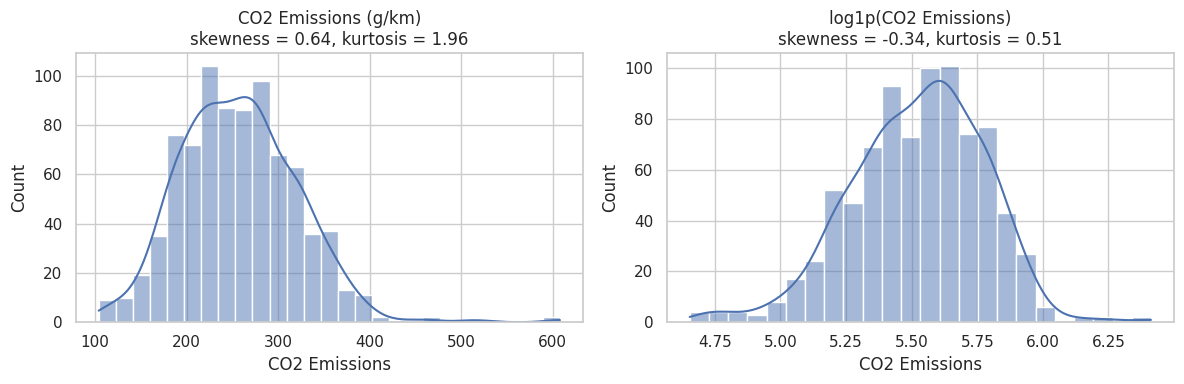

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, s) in zip(axes, {"CO2 Emissions (g/km)": fuel_df["CO2 Emissions"],
                                "log1p(CO2 Emissions)": np.log1p(fuel_df["CO2 Emissions"])}.items()):
    sns.histplot(s, kde=True, ax=ax)
    ax.set_title(f"{name}\nskewness = {s.skew():.2f}, kurtosis = {s.kurt():.2f}")
plt.tight_layout()
plt.show()

Pe datele originale, distribuția este asimetrică la dreapta (skewness ≈ 0,64), iar după logaritmare asimetria scade. De aceea vom modela `log1p(CO2 Emissions)`.

**De ce `log1p` și nu `log`?** `log1p(x) = log(1 + x)` este definit și pentru x = 0 și are inversa `expm1`. La valori mari ca cele de aici, diferența față de `log` este neglijabilă.

### Corelații între variabilele numerice

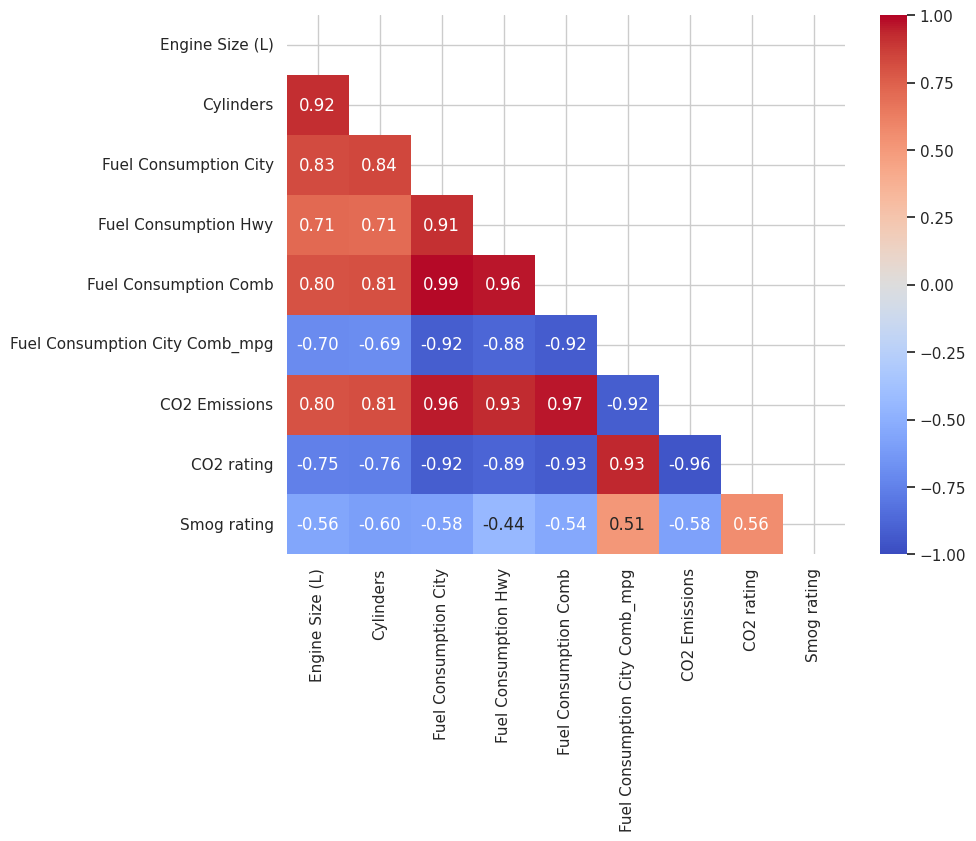

In [ ]:
corr = fuel_df.select_dtypes("number").corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool)), ax=ax)
plt.show()

Toate variabilele de consum și motor sunt puternic corelate cu emisiile, dar **sunt corelate și între ele**.
Trei lucruri de reținut pentru restul laboratorului:

1. **Multicoliniaritate.** `Fuel Consumption Comb` este (aproximativ) o medie ponderată între `City` și `Hwy`, iar `..._mpg` este aceeași mărime exprimată în alte unități (mpg ≈ 235,2 / L/100 km). Aceste variabile se „dublează” între ele.
2. **Data leakage.** `CO2 rating` este o notă calculată *direct din emisiile de CO₂*. A o folosi ca variabilă explicativă înseamnă a folosi răspunsul pentru a prezice răspunsul. O vom exclude (și vom măsura cât de mult ne-ar „ajuta” să trișăm).
3. Corelația puternică nu înseamnă cauzalitate, iar un R² mare pe date de acest tip nu spune nimic despre vehicule din altă țară sau din alt an.

## 3. Regresia liniară simplă

Modelul: $\ln(1+CO_2) = \beta_0 + \beta_1 \cdot \ln(1+\text{Fuel Consumption Comb}) + \varepsilon$

Logaritmăm și variabila explicativă, deci modelul este de tip **log-log**: $\beta_1$ se interpretează aproximativ ca o *elasticitate* (cu cât % cresc emisiile când consumul crește cu 1%).

### 3.1 Împărțirea în set de antrenare și set de testare

Modelul se **antrenează** pe un set și se **testează** pe date pe care nu le-a văzut, pentru a estima cât de bine generalizează.
Folosim 80% pentru antrenare și 20% pentru testare, cu `train_test_split` (amestecare aleatoare, `random_state` fix pentru reproductibilitate).

*Notă:* logaritmarea nu învață nimic din date (nu are parametri), deci o putem aplica înainte de împărțire fără risc de *leakage*. Scalările (StandardScaler) însă **se învață doar pe train** – vom folosi pipeline-uri pentru asta în secțiunea 5.

In [ ]:
X = np.log1p(fuel_df[["Fuel Consumption Comb"]])
y = np.log1p(fuel_df["CO2 Emissions"])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Antrenare:", X_tr.shape, "| Testare:", X_te.shape)

Antrenare: (666, 1) | Testare: (167, 1)


### 3.2 Antrenarea modelului

In [ ]:
regr = LinearRegression()
regr.fit(X_tr, y_tr)
print(f"Intercept (β0) = {regr.intercept_:.4f}")
print(f"Panta (β1)     = {regr.coef_[0]:.4f}")

Intercept (β0) = 2.9589
Panta (β1)     = 1.0421


Scikit-learn estimează parametrii prin **metoda celor mai mici pătrate (OLS)**: alege β care minimizează suma pătratelor erorilor $\sum (y_i - \hat y_i)^2$ pe setul de antrenare.
Ea oferă coeficienții, dar **nu** oferă teste statistice. Pentru *t-statistic*, *p-value* și intervale de încredere folosim `statsmodels`.

In [ ]:
ols = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
print(ols.summary().tables[1])
print(f"R² (train) = {ols.rsquared:.4f}")

                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     2.9589      0.021    142.671      0.000       2.918       3.000
Fuel Consumption Comb     1.0421      0.008    124.274      0.000       1.026       1.059
R² (train) = 0.9588


**Cum citim tabelul:** `coef` = estimarea parametrului; `std err` = eroarea standard a estimării; `t` = coef / std err; `P>|t|` = p-value pentru ipoteza H₀: β = 0; `[0.025 0.975]` = intervalul de încredere de 95%.
Dacă p-value < 0,05 (sau 0,01), parametrul este **semnificativ statistic** la acel nivel.

**Interpretare.** Panta este apropiată de 1: o creștere de 1% a consumului combinat este asociată cu o creștere de circa 1% a emisiilor – ceea ce are sens fizic, deoarece CO₂ rezultă direct din combustibilul ars. Panta este semnificativă (p-value practic 0).

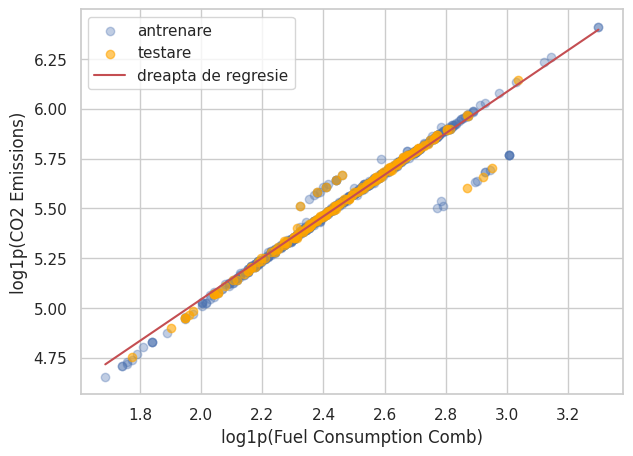

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_tr.iloc[:, 0], y_tr, alpha=0.35, label="antrenare")
ax.scatter(X_te.iloc[:, 0], y_te, alpha=0.6, color="orange", label="testare")
xs = np.linspace(X.iloc[:, 0].min(), X.iloc[:, 0].max(), 100)
ax.plot(xs, regr.intercept_ + regr.coef_[0] * xs, "r-", label="dreapta de regresie")
ax.set_xlabel("log1p(Fuel Consumption Comb)")
ax.set_ylabel("log1p(CO2 Emissions)")
ax.legend()
plt.show()

### 3.3 Evaluarea modelului

Comparăm valorile reale cu cele prezise **pe setul de testare**:

| Măsură | Ce spune |
|---|---|
| **MAE** – eroarea absolută medie | eroarea tipică, ușor de interpretat |
| **MSE** – media pătratelor erorilor | penalizează puternic erorile mari |
| **RMSE** – $\sqrt{MSE}$ | aceeași unitate ca ținta; util pentru compararea modelelor |
| **R²** | proporția din variația țintei explicată de model; 1 = perfect, poate fi și negativ (model mai prost decât media) |

Atenție: pe scara logaritmică, erorile sunt **relative** (≈ procente), iar interpretabil pentru oameni este tabelul în **g/km**.

In [ ]:
y_hat = regr.predict(X_te)
metrics_log_and_original(y_te, y_hat)

,scara log,g/km (scara reală)
MAE,0.0218,6.0507
MSE,0.0029,293.0961
RMSE,0.0538,17.1200
R2,0.9509,0.9173


### 3.4 Folosirea modelului: o predicție nouă

In [ ]:
# Ce emisii prezice modelul pentru o mașină cu un consum combinat de 9,0 L/100 km?
new_car = pd.DataFrame({"Fuel Consumption Comb": [np.log1p(9.0)]})
pred_log = regr.predict(new_car)
print(f"Emisii prezise: {np.expm1(pred_log)[0]:.0f} g/km")

Emisii prezise: 211 g/km


### ✍️ Exercițiul 1 ⭐

Repetați analiza din secțiunea 3, dar cu **`Engine Size (L)`** ca variabilă explicativă:

1. construiți `X` și `y` (cu `log1p`), împărțiți train/test cu același `random_state`;
2. antrenați un `LinearRegression` și afișați interceptul și panta;
3. estimați modelul și cu `statsmodels` și interpretați panta și p-value;
4. calculați indicatorii de evaluare cu `metrics_log_and_original`;
5. **Comparați** R² și RMSE (în g/km) cu modelul bazat pe `Fuel Consumption Comb`. Care variabilă explică mai bine emisiile? De ce credeți că este așa?

*Bonus:* repetați pentru `Cylinders` și rezumați cele trei modele într-un singur `DataFrame`.

In [ ]:
# Codul vostru aici

## 4. Regresia liniară multiplă

Folosim trei variabile explicative (toate cu `log1p`): `Engine Size (L)`, `Cylinders`, `Fuel Consumption Comb`.

In [ ]:
feat_mlr = ["Engine Size (L)", "Cylinders", "Fuel Consumption Comb"]
X = np.log1p(fuel_df[feat_mlr])
y = np.log1p(fuel_df["CO2 Emissions"])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

mlr = LinearRegression().fit(X_tr, y_tr)
print(f"Intercept: {mlr.intercept_:.4f}")
print(pd.Series(mlr.coef_, index=feat_mlr).round(4))

Intercept: 2.9543
Engine Size (L)         -0.0266
Cylinders                0.0616
Fuel Consumption Comb    1.0125
dtype: float64


### 4.1 Semnificația coeficienților

În regresia multiplă, eroarea standard a unui coeficient depinde de **corelațiile dintre variabilele explicative**, de aceea nu o mai putem calcula cu formula simplă din regresia simplă. Folosim direct `statsmodels`.

In [ ]:
ols_m = sm.OLS(y_tr, sm.add_constant(X_tr)).fit()
print(ols_m.summary().tables[1])
print(f"R² (train) = {ols_m.rsquared:.4f} | R² ajustat = {ols_m.rsquared_adj:.4f}")

                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     2.9543      0.025    116.293      0.000       2.904       3.004
Engine Size (L)          -0.0266      0.019     -1.409      0.159      -0.064       0.010
Cylinders                 0.0616      0.021      2.939      0.003       0.020       0.103
Fuel Consumption Comb     1.0125      0.014     70.568      0.000       0.984       1.041
R² (train) = 0.9595 | R² ajustat = 0.9593


Interpretați tabelul: care coeficienți sunt semnificativi? Ce semn are fiecare?

> În rularea originală a acestui laborator, coeficientul lui `Engine Size` a ieșit **negativ**, adică „motoarele mai mari ar polua mai puțin”, ceea ce e contraintuitiv. Verificați dacă vedeți același lucru. Un semn „greșit” este un indiciu clasic de **multicoliniaritate**; o verificăm imediat.

### 4.2 Multicoliniaritatea – VIF

**VIF** (*Variance Inflation Factor*) măsoară cât de bine poate fi prezisă o variabilă explicativă din celelalte. Reguli orientative: VIF > 5 – atenție; VIF > 10 – problemă serioasă (coeficienții devin instabili și greu de interpretat, deși predicțiile pot rămâne bune).

In [ ]:
Xc = sm.add_constant(X_tr)
vif = pd.DataFrame({
    "variabila": X_tr.columns,
    "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X_tr.shape[1])],
}).round(2)
vif

,variabila,VIF
0,Engine Size (L),8.21
1,Cylinders,8.29
2,Fuel Consumption Comb,2.97


### 4.3 Diagnosticul reziduurilor

Reziduurile $e_i = y_i - \hat y_i$ ar trebui să fie: fără structură față de valorile prezise, cu varianță aproximativ constantă (**homoscedasticitate**) și aproximativ normale.

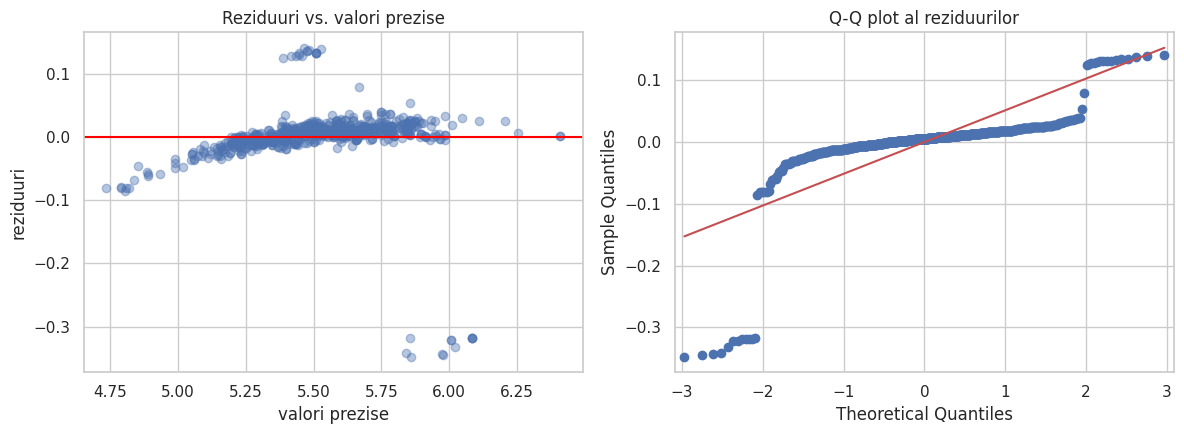

Breusch-Pagan (omogenitatea varianței): p-value = 0.0000  (p < 0.05 → indicii de heteroscedasticitate)
Durbin-Watson = 2.011


In [ ]:
resid, fitted = ols_m.resid, ols_m.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(fitted, resid, alpha=0.4)
axes[0].axhline(0, color="red")
axes[0].set(xlabel="valori prezise", ylabel="reziduuri", title="Reziduuri vs. valori prezise")
sm.qqplot(resid, line="s", ax=axes[1])
axes[1].set_title("Q-Q plot al reziduurilor")
plt.tight_layout()
plt.show()

lm_stat, lm_p, _, _ = het_breuschpagan(resid, ols_m.model.exog)
print(f"Breusch-Pagan (omogenitatea varianței): p-value = {lm_p:.4f}  (p < 0.05 → indicii de heteroscedasticitate)")
print(f"Durbin-Watson = {durbin_watson(resid):.3f}")

**Despre Durbin-Watson.** Statistica DW (≈ 2 = fără autocorelare) are sens când observațiile au o **ordine naturală** (serii de timp). Aici rândurile sunt vehicule fără o ordine temporală, deci valoarea ei este doar orientativă. Mult mai informative sunt graficele de mai sus și testul Breusch-Pagan.

### 4.4 Evaluare pe setul de testare

In [ ]:
y_hat = mlr.predict(X_te)
metrics_log_and_original(y_te, y_hat)

,scara log,g/km (scara reală)
MAE,0.0235,6.4224
MSE,0.0029,290.1038
RMSE,0.0538,17.0324
R2,0.9509,0.9182


Modelul multiplu nu este spectaculos de diferit de cel simplu: `Fuel Consumption Comb` conține deja aproape toată informația utilă. Variabilele adăugate aduc puțin și introduc multicoliniaritate.

### 4.5 Validarea încrucișată (cross-validation)

Un singur `train_test_split` poate fi norocos sau ghinionist. Să vedem cât variază R² doar schimbând `random_state`:

In [ ]:
r2_splits = []
for seed in range(10):
    a, b, c_, d = train_test_split(X, y, test_size=0.2, random_state=seed)
    r2_splits.append(LinearRegression().fit(a, c_).score(b, d))
print("R² pe 10 împărțiri diferite:", np.round(r2_splits, 4))
print(f"Amplitudine: {max(r2_splits) - min(r2_splits):.4f}")

R² pe 10 împărțiri diferite: [0.9325 0.9626 0.9574 0.9162 0.9697 0.9398 0.9456 0.9555 0.943  0.952 ]
Amplitudine: 0.0534


**K-fold cross-validation**: datele se împart în *k* părți; pe rând, fiecare parte este set de testare, iar restul de antrenare. Raportăm media și deviația standard a celor *k* scoruri, o estimare mai stabilă a performanței.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(LinearRegression(), X, y, cv=kf, scoring="r2")
print("R² pe fiecare fold:", scores.round(4))
print(f"R² mediu = {scores.mean():.4f} ± {scores.std():.4f}")

R² pe fiecare fold: [0.9509 0.9435 0.9205 0.9907 0.9645]
R² mediu = 0.9540 ± 0.0232


### ✍️ Exercițiul 2 ⭐⭐

Verificați dacă **mai multe variabile înseamnă un model mai bun**.

1. Construiți un model multiplu cu toate cele 6 variabile numerice de motor și consum: `Engine Size (L)`, `Cylinders`, `Fuel Consumption City`, `Fuel Consumption Hwy`, `Fuel Consumption Comb`, `Fuel Consumption City Comb_mpg` (toate cu `log1p`).
2. Calculați **VIF** pentru fiecare. Ce observați? Corelați cu ce ați aflat din heatmap despre aceste variabile.
3. Estimați modelul cu `statsmodels` și priviți coeficienții: sunt toți semnificativi? Au semnele așteptate?
4. Comparați, prin **cross-validation cu 5 foldy** (R² mediu), modelul cu 3 variabile din secțiunea 4 și cel cu 6 variabile.
5. Formulați în 2–3 propoziții concluzia: merită variabilele suplimentare? Ce ar trebui făcut cu variabilele redundante?

In [ ]:
# Codul vostru aici

## 5. Regularizarea: Ridge, Lasso, ElasticNet

Când avem multe variabile (mai ales corelate), OLS poate supraînvăța și poate da coeficienți instabili. **Regularizarea** adaugă o penalizare pe mărimea coeficienților:

- **Ridge (L2):** $\min \sum (y_i-\hat y_i)^2 + \alpha \sum \beta_j^2$ – micșorează coeficienții, dar rareori îi face exact 0; stabil la multicoliniaritate.
- **Lasso (L1):** $\min \sum (y_i-\hat y_i)^2 + \alpha \sum |\beta_j|$ – poate aduce coeficienți **exact la 0**, deci face și *selecție de variabile*.
- **ElasticNet:** combinație între cele două, controlată de `l1_ratio`.

Hiperparametrul $\alpha$ (cât de puternică e penalizarea) se alege prin **validare încrucișată** – exact ce fac `RidgeCV`, `LassoCV`, `ElasticNetCV`.

**Două reguli practice, esențiale:**
1. Penalizarea depinde de scara variabilelor, deci **variabilele numerice trebuie standardizate** (`StandardScaler`) înainte de Ridge/Lasso.
2. Standardizarea și codificarea one-hot se învață **doar pe datele de antrenare**. Pentru a nu greși, le punem într-un `Pipeline`, care aplică automat transformările corecte și la testare.

### 5.1 Pregătirea datelor

- **Variabile numerice** → `StandardScaler`.
- **Variabile categoriale** (`Make`, `Vehicle Class`, `Transmission`, `Fuel type`) → `OneHotEncoder` (cu `handle_unknown="ignore"`, ca să nu pice modelul la o categorie nevăzută la antrenare).
- **Ținta** → `log1p`, aplicat automat prin `TransformedTargetRegressor` (predicțiile revin singure în g/km).
- **Excluse:** `CO2 rating` (leakage) și `Model` (prea multe categorii; revenim în exercițiul 6).

In [ ]:
target = "CO2 Emissions"

num_cols = ["Engine Size (L)", "Cylinders", "Fuel Consumption City", "Fuel Consumption Hwy",
            "Fuel Consumption Comb", "Fuel Consumption City Comb_mpg", "Smog rating"]
cat_cols = ["Make", "Vehicle Class", "Transmission", "Fuel type"]
FEATURES = num_cols + cat_cols

# O singură împărțire train/test pentru toată secțiunea de regularizare
X_train_all, X_test_all, y_train, y_test = train_test_split(
    fuel_df.drop(columns=[target]), fuel_df[target], test_size=0.2, random_state=RANDOM_STATE)
X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def build_model(estimator, num_cols=num_cols, cat_cols=cat_cols):
    """Pipeline complet: scalare + one-hot -> estimator, cu ținta logaritmată automat.
    TransformedTargetRegressor aplică log1p la antrenare și expm1 la predicție,
    deci predicțiile și erorile sunt direct în g/km."""
    prep = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep), ("model", estimator)]),
        func=np.log1p, inverse_func=np.expm1)


def evaluate_model(model, X_tr=None, X_te=None):
    """Antrenează modelul și întoarce un rând de rezultate (CV pe train + test), în g/km."""
    X_tr = X_train if X_tr is None else X_tr
    X_te = X_test if X_te is None else X_te
    cv_rmse = -cross_val_score(model, X_tr, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    return pd.Series({
        "RMSE CV (medie)": cv_rmse.mean(),
        "RMSE test": rmse(y_test, pred),
        "MAE test": mean_absolute_error(y_test, pred),
        "R2 test": r2_score(y_test, pred),
    })


def coef_table(fitted_model):
    """Coeficienții modelului antrenat, sortați după valoarea absolută."""
    pipe = fitted_model.regressor_
    names = pipe.named_steps["prep"].get_feature_names_out()
    return pd.Series(pipe.named_steps["model"].coef_, index=names).sort_values(key=np.abs, ascending=False)

### 5.2 Trei modele, aceeași evaluare

In [ ]:
models = {
    "OLS": build_model(LinearRegression()),
    "Ridge": build_model(RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5)),
    "Lasso": build_model(LassoCV(alphas=np.logspace(-4, 0, 40), cv=5, max_iter=20000, random_state=RANDOM_STATE)),
}

results = pd.DataFrame({name: evaluate_model(m) for name, m in models.items()}).T
results.round(3).sort_values("RMSE test")

,RMSE CV (medie),RMSE test,MAE test,R2 test
Lasso,3.257,2.444,1.898,0.998
OLS,3.153,2.506,1.802,0.998
Ridge,3.126,2.520,1.818,0.998


Toate valorile sunt în **g/km** (cu excepția R²). `RMSE CV` este media pe 5 foldy *în interiorul setului de antrenare*, iar `RMSE test` este calculat pe setul de testare, folosit o singură dată, la final.

Hiperparametrii aleși prin validare încrucișată:

In [ ]:
print(f"Ridge: alpha = {models['Ridge'].regressor_.named_steps['model'].alpha_:.4f}")
print(f"Lasso: alpha = {models['Lasso'].regressor_.named_steps['model'].alpha_:.5f}")

Ridge: alpha = 0.0518
Lasso: alpha = 0.00010


### 5.3 Ce a învățat fiecare model? Coeficienții

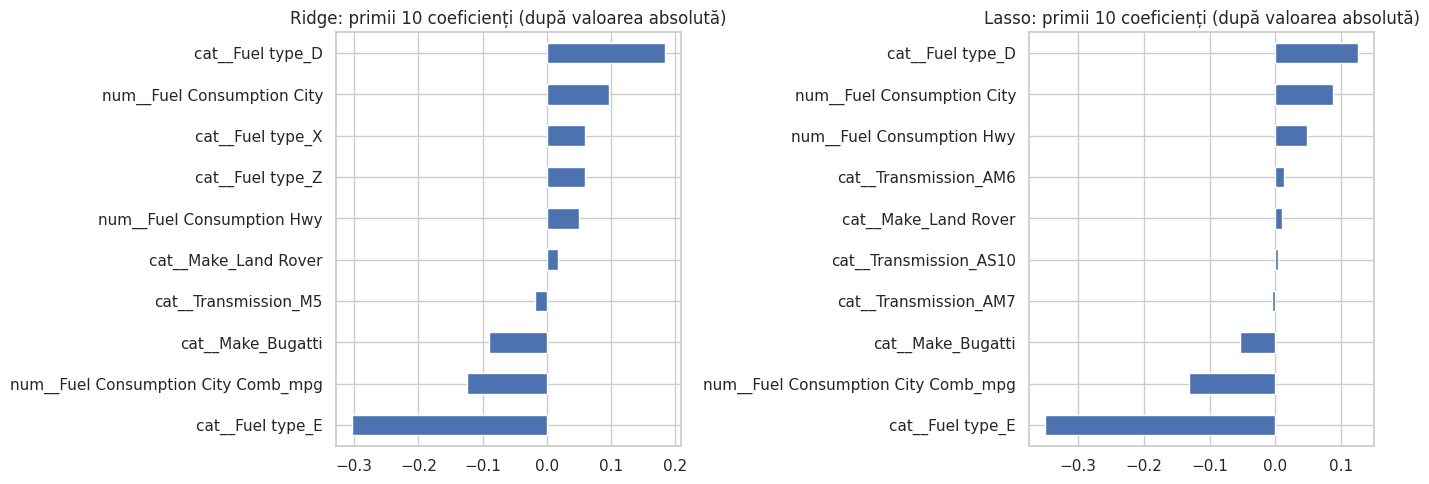

Lasso: 47 din 86 coeficienți sunt exact 0 → variabile eliminate


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    coef_table(models[name]).head(10).sort_values().plot.barh(ax=ax)
    ax.set_title(f"{name}: primii 10 coeficienți (după valoarea absolută)")
plt.tight_layout()
plt.show()

lasso_coefs = coef_table(models["Lasso"])
print(f"Lasso: {int((lasso_coefs == 0).sum())} din {len(lasso_coefs)} coeficienți sunt exact 0 → variabile eliminate")

Datorită standardizării, coeficienții variabilelor numerice sunt comparabili între ei (efect asupra `log1p(CO2)` la o creștere de o deviație standard). Observați cum Lasso „taie” variabile redundante, în timp ce Ridge le păstrează pe toate, dar mai mici.

> Înainte, laboratorul folosea biblioteca `eli5` pentru a afișa ponderile. Aceasta nu mai este întreținută și se strică la versiuni noi de scikit-learn, așa că calculăm direct coeficienții din pipeline.

### 5.4 Valori prezise vs. reale, în g/km

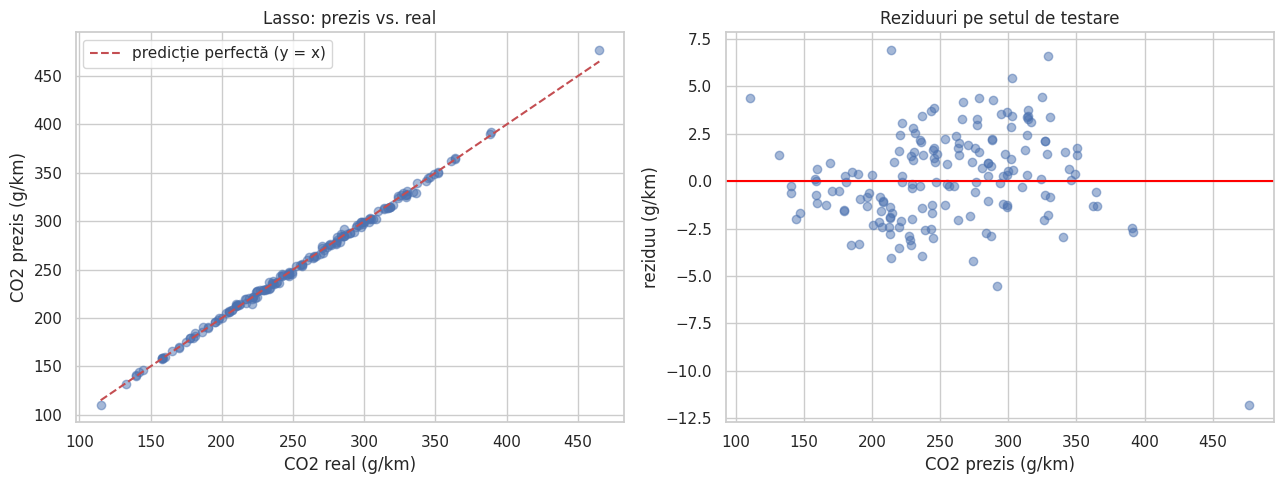

In [ ]:
best_name = results["RMSE test"].idxmin()
best = models[best_name]
pred = best.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="predicție perfectă (y = x)")
axes[0].set(xlabel="CO2 real (g/km)", ylabel="CO2 prezis (g/km)", title=f"{best_name}: prezis vs. real")
axes[0].legend()

axes[1].scatter(pred, y_test - pred, alpha=0.5)
axes[1].axhline(0, color="red")
axes[1].set(xlabel="CO2 prezis (g/km)", ylabel="reziduu (g/km)", title="Reziduuri pe setul de testare")
plt.tight_layout()
plt.show()

In [ ]:
# Salvarea predicțiilor într-un fișier CSV
pd.DataFrame({"id": X_test.index, "CO2 real": y_test.values, "CO2 prezis": pred.round(1)}) \
    .to_csv(f"predictii_{best_name.lower()}.csv", index=False)

### 5.5 Experiment: ce se întâmplă dacă „trișăm” cu `CO2 rating`?

Comparăm același model Ridge cu și fără variabila care este derivată din țintă.

In [ ]:
rows = {}
for label, cols in {"fără CO2 rating (corect)": num_cols,
                    "cu CO2 rating (leakage!)": num_cols + ["CO2 rating"]}.items():
    m = build_model(RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5), num_cols=cols)
    rows[label] = evaluate_model(m, X_train_all[cols + cat_cols], X_test_all[cols + cat_cols])
pd.DataFrame(rows).T.round(3)

,RMSE CV (medie),RMSE test,MAE test,R2 test
fără CO2 rating (corect),3.126,2.520,1.818,0.998
cu CO2 rating (leakage!),3.141,2.517,1.813,0.998


Dacă scorurile par „mai bune”, nu înseamnă că modelul e mai bun: la o mașină nouă, *rating-ul CO₂ nu există înainte să măsurăm emisiile*. Un model util trebuie să folosească doar informații disponibile **în momentul predicției**.

### ✍️ Exercițiul 3 ⭐⭐ – Folosiți modelul

Creați un **vehicul ipotetic** (alegeți voi valorile) sub forma unui `DataFrame` cu un singur rând și exact coloanele din `X_train.columns`. Apoi:

1. obțineți predicția de CO₂ (g/km) cu fiecare dintre cele 3 modele (`OLS`, `Ridge`, `Lasso`) antrenate mai sus;
2. variați *un singur parametru* (de exemplu `Engine Size (L)` de la 1,5 la 5,0, restul constante) și reprezentați grafic emisiile prezise;
3. încercați o valoare de `Make` care nu apare în date. Ce se întâmplă și de ce nu pică modelul?

In [ ]:
# Codul vostru aici

### ✍️ Exercițiul 4 ⭐⭐ – Variabile categoriale în regresia liniară

Variabila `Fuel type` conține tipul de combustibil. Estimați cu **`statsmodels`** modelul:

$\ln(1+CO_2) = \beta_0 + \beta_1 \ln(1+\text{Fuel Consumption Comb}) + \sum \gamma_k \cdot \text{FuelType}_k + \varepsilon$

Indicii: aflați categoriile cu `fuel_df["Fuel type"].value_counts()`; creați variabilele binare cu `pd.get_dummies(..., drop_first=True, dtype=float)`; adăugați constanta cu `sm.add_constant`.

1. De ce folosim `drop_first=True` (ce s-ar întâmpla în OLS dacă am păstra toate categoriile, împreună cu constanta)?
2. Care este categoria de referință? Interpretați coeficienții $\gamma_k$ (indiciu: într-un model cu țintă logaritmată, $e^{\gamma}-1$ ≈ diferența procentuală față de categoria de referință, la același consum).
3. Sunt diferențele între tipurile de combustibil semnificative statistic? Au sens fizic?

In [ ]:
# Codul vostru aici

### ✍️ Exercițiul 5 ⭐⭐⭐ – ElasticNet

Folosiți `ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], alphas=np.logspace(-4, 0, 40), cv=5, max_iter=20000)` în același pipeline (`build_model`).

1. Evaluați-l cu `evaluate_model` și adăugați rezultatul ca nou rând în tabelul `results`.
2. Afișați `l1_ratio_` și `alpha_` alese. Ce spune `l1_ratio_` apropiat de 1 sau de 0 despre ce tip de penalizare preferă datele?
3. Câți coeficienți sunt exact 0 la ElasticNet, comparativ cu Lasso?

In [ ]:
# Codul vostru aici

### ✍️ Exercițiul 6 ⭐⭐⭐ – Prea multe categorii

Variabila `Model` (numele modelului de mașină) are sute de valori distincte.

1. Construiți un pipeline Lasso în care adăugați `Model` la `cat_cols` (atenție: trebuie să selectați coloana și în `X_train`/`X_test`, pornind de la `X_train_all`/`X_test_all`).
2. Câte variabile are acum matricea transformată (`get_feature_names_out()`), față de modelul de bază?
3. Comparați `RMSE CV` și `RMSE test`. Apare o diferență mare între ele? Cum se leagă asta de **supraînvățare**?
4. Câți coeficienți Lasso rămân nenuli?

In [ ]:
# Codul vostru aici

### ✍️ Exercițiul 7 ⭐⭐⭐ – Importanța variabilelor prin permutare

Coeficienții depind de scară și sunt înșelători pentru variabile corelate. O alternativă este **importanța prin permutare**: se amestecă aleator valorile unei coloane din setul de test și se măsoară cât crește eroarea.

Folosiți `sklearn.inspection.permutation_importance` pe modelul Lasso antrenat (`models["Lasso"]`), cu `X_test`, `y_test`, `scoring="neg_root_mean_squared_error"`, `n_repeats=10`, `random_state=RANDOM_STATE`.

1. Afișați primele 5 variabile (original features, nu coloanele one-hot), cu media și deviația standard.
2. Sunt aceleași variabile ca cele cu cei mai mari coeficienți? Explicați eventualele diferențe.

In [ ]:
# Codul vostru aici

## 6. Provocare finală ⭐⭐⭐ (mini-proiect individual)

Dorim să estimăm **consumul combinat** (`Fuel Consumption Comb`) al unui vehicul **înainte** de a fi măsurat, doar din caracteristicile sale constructive:
`Engine Size (L)`, `Cylinders`, `Make`, `Vehicle Class`, `Transmission`, `Fuel type`.

Cerințe:
1. Justificați de ce nu putem folosi `Fuel Consumption City/Hwy`, `..._mpg`, `CO2 Emissions` și `CO2 rating` ca variabile explicative.
2. Construiți un pipeline (adaptând `build_model`) și comparați cel puțin **OLS, Ridge și Lasso** prin cross-validation.
3. Raportați pe setul de testare RMSE și MAE în L/100 km și un grafic prezis vs. real.
4. Scrieți 5–6 rânduri: care sunt variabilele cele mai influente, cât de bun este modelul și ce limite are.

## 7. Întrebări de verificare

1. De ce împărțim datele în train și test? Ce ar însemna să evaluăm modelul pe datele pe care l-am antrenat?
2. Ce înseamnă R² = 0,92? Poate fi negativ? Când?
3. De ce a ieșit coeficientul pentru `Engine Size` cu semn „greșit” în modelul multiplu? Cum am verificat cauza?
4. De ce standardizăm variabilele înainte de Lasso/Ridge, dar nu e necesar pentru OLS simplu?
5. Care este diferența practică dintre Ridge și Lasso? Când ați alege fiecare?
6. Ce este *data leakage*? Dați un exemplu din acest laborator.
7. De ce raportăm metricile în g/km, deși modelul a fost antrenat pe `log1p(CO2)`?